# Summary · upscale, frame extrapolation, frame interpolation

This notebook covers the three problems of this repo, each in the same order: **the baseline** a model has to beat,
**the model picked** for desktop-streamer's client, how well it does (**PSNR and SSIM**), how long it takes (**time in
the browser**), and **a block diagram of the picked graph**.

**Nothing here is measured again.** Every number is copied from a result a notebook has already printed: its saved
output, or its own write-up in `<problem>/summary.md`. Each table names its source. This notebook trains nothing, reads
no data and runs no model. It needs only numpy, pandas and matplotlib.

**Units**
- **PSNR-Y** is PSNR of luma (Y′), in dB. **wPSNR** is PSNR over Y′CbCr with luma weighted six times either chroma
  channel (`helpers/metrics.py`); it is the frame generators' headline score. Higher is better for both.
- **SSIM-Y** is the structural similarity of luma, from 0 to 1, higher is better. It penalises blur that PSNR forgives.
- **Time** is the exported ONNX graph in Chrome's WebGPU on the RTX 3090, timed on the benchmark page
  (`upscale/benchmark/`), unless a chart says otherwise. GTX 1660 Ti numbers are marked *measured* (on that laptop) or
  *predicted* (from the 3090).
- **95% ranges** for the frame generators are the notebooks' bootstraps over videos (over clips for the drawn kinds).

**Only methods the client can run.** No result here uses the frame it is trying to make, nor anything the host would
have to send.

## At a glance

| | Upscale | Frame extrapolation | Frame interpolation |
|---|---|---|---|
| **In → out** | the stream at half size → ×2 | received N−2, N → the unsent N+1, no added latency | received N, N+2 → the unsent N+1, shown half an interval late |
| **Baseline** | bicubic, which the GPU's sampler does for free | repeat N; the old mock, `2·N − (N−2)` | the old mock, the mean of N and N+2; hold N |
| **Picked graph** | `dist/upscale/client/upscale.onnx`, the told 24×2 (notebooks 22–23); `upscale_fast.onnx`, the q24 (notebook 24), for a GTX 1660 Ti | `dist/frame_gen_extra/extrapolate2x_tilesearch_decide_r4_s2.onnx`, a tile search with a carry-or-repeat decision (notebook 13) | `dist/frame_gen_intra/interpolate2x_tilesearch_r4_s2.onnx`, a two-sided tile search (notebooks 1, 3) |
| **Quality** | SSIM-Y 0.9289 against bicubic's 0.9045; PSNR-Y 35.07 against 33.55 dB | wPSNR 38.99 against repeat's 37.62 dB on moving client tiles | wPSNR 40.55 against the mean's 38.15 dB on moving client tiles |
| **Time, RTX 3090** | 6.65–6.95 ms for a 1280×720 stream's 16 tiles; q24 1.35–1.41 ms | 2.75 ms a 1080p frame | 3.3 ms a 1080p frame |

In [1]:
"""Style, the colour of each role, and the helpers every chart below uses."""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle

pd.set_option("display.width", 160)

SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
# A colour says what a method is in the comparison, the same in every chart. The method's name is always on the axis or in the
# legend, and each one also has its own marker shape, so no chart relies on colour alone.
ROLE = {"baseline": "#6b6a65",   # the bar to beat, or what the client ran before
        "picked": "#2a78d6",     # the graph desktop-streamer runs
        "alt": "#eb6834",        # tried, not picked
        "alt2": "#1baf7a",       # a second one tried, where two share a chart
        "other": "#b5b4ae"}      # the rest, in the background
MARKER = {"baseline": "s", "picked": "o", "alt": "D", "alt2": "^", "other": "o"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 9, "figure.titlesize": 11, "figure.titleweight": "semibold",
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": RULE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": INK, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": RULE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 8.5, "legend.handletextpad": 0.3, "legend.columnspacing": 1.6,
})


def title(fig, text):
    fig.suptitle(text, x=0.01, ha="left")


def key(fig, entries, columns=None):
    """A legend under the figure: `entries` maps a label to its role."""
    handles = [Line2D([], [], ls="", marker=MARKER[role], markersize=7, color=ROLE[role], label=label)
               for label, role in entries.items()]
    fig.legend(handles=handles, loc="outside lower center", ncol=columns or len(handles))


def note(value, x, y, dx=8, ax=None, **kw):
    """A value written beside a mark: right of it, or left with a negative `dx`. A real minus sign."""
    (ax or plt.gca()).annotate(value.replace("-", "−"), (x, y), xytext=(dx, 0), textcoords="offset points",
                               va="center", ha="left" if dx > 0 else "right", fontsize=8.5, color=INK, **kw)


def dots(ax, values, roles, xlabel, reference=None, fmt="{:.2f}", labelled=("baseline", "picked")):
    """A dot plot: one row per method, top to bottom in the order given, the dot coloured by role. With a `reference`
    (the baseline's value) each dot hangs on a stem from it, so the stem is the gain. Values are written out for the
    `labelled` roles only; the table under the chart holds the rest."""
    rows = np.arange(len(values))[::-1]
    for row, (name, value), role in zip(rows, values.items(), roles):
        if reference is not None:
            ax.plot([reference, value], [row, row], color=ROLE[role], lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(value, row, s=64, color=ROLE[role], marker=MARKER[role], edgecolors=SURFACE, linewidths=1.5,
                   zorder=3)
        if role in labelled:   # on the side away from the stem
            note(fmt.format(value), value, row, ax=ax, dx=-8 if reference is not None and value < reference else 8)
    ax.set_yticks(rows, values.index)
    ax.set_ylim(-0.7, len(values) - 0.3)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.22)   # room for a value written on either side


def dodged(ax, table, series, xlabel, fmt="{:.2f}", labelled_row=None):
    """Rows of `table` on the y axis, one dot per column in `series` (column -> role), nudged apart so none hides
    another. With `labelled_row`, the picked series' value in that row is written out."""
    rows = np.arange(len(table))[::-1]
    nudge = np.linspace(0.22, -0.22, len(series))
    for (column, role), dy in zip(series.items(), nudge):
        ax.scatter(table[column], rows + dy, s=50, color=ROLE[role], marker=MARKER[role], edgecolors=SURFACE,
                   linewidths=1.2, zorder=3)
        if labelled_row is not None and role == "picked":
            row = len(table) - 1 - list(table.index).index(labelled_row)
            note(fmt.format(table.loc[labelled_row, column]), table.loc[labelled_row, column], row + dy, ax=ax)
    for row in rows[:-1]:
        ax.axhline(row - 0.5, color=RULE, lw=0.6, zorder=0)
    ax.set_yticks(rows, table.index)
    ax.set_ylim(-0.6, len(table) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.08)


def forest(ax, table, roles, xlabel, labelled=("baseline", "picked")):
    """Gains with their 95% ranges: `table` has the columns gain, low and high (NaN where a notebook gave no range)."""
    rows = np.arange(len(table))[::-1]
    ax.axvline(0, color=MUTED, lw=0.9, zorder=1)
    for row, (name, r), role in zip(rows, table.iterrows(), roles):
        if pd.notna(r["low"]):
            ax.plot([r["low"], r["high"]], [row, row], color=ROLE[role], lw=1.8, solid_capstyle="round", zorder=2)
        ax.scatter(r["gain"], row, s=60, color=ROLE[role], marker=MARKER[role], edgecolors=SURFACE, linewidths=1.5,
                   zorder=3)
        if role in labelled:
            end = r["high"] if pd.notna(r["high"]) else r["gain"]
            note(f"{r['gain']:+.2f}", end, row, ax=ax)
    ax.set_yticks(rows, table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.1)


def timebars(ax, table, xlabel, budget=None, budget_label=None):
    """Horizontal bars of milliseconds from zero. `table` has ms, role, and optionally low/high (a measured range,
    drawn as a whisker) and predicted (drawn hollow and hatched: not a measurement)."""
    rows = np.arange(len(table))[::-1]
    widest = max(table[["ms"] + [c for c in ("high",) if c in table]].max(axis=None), budget or 0)
    for row, (name, r) in zip(rows, table.iterrows()):
        colour, predicted = ROLE[r["role"]], bool(r.get("predicted", False))
        ax.barh(row, r["ms"], height=0.58, color=SURFACE if predicted else colour, edgecolor=colour,
                hatch="////" if predicted else None, linewidth=1.2 if predicted else 0, zorder=2)
        low, high = r.get("low", np.nan), r.get("high", np.nan)
        if pd.notna(low):
            ax.plot([low, high], [row, row], color=INK, lw=1.2, zorder=3)
            ax.plot([low, low], [row - 0.12, row + 0.12], color=INK, lw=1.2, zorder=3)
            ax.plot([high, high], [row - 0.12, row + 0.12], color=INK, lw=1.2, zorder=3)
            text = f"{low:g}–{high:g} ms" + (" predicted" if predicted else "")
        else:
            high, text = r["ms"], f"{r['ms']:g} ms"
        if budget is not None and 0 < budget - high < 0.05 * widest:
            high = budget   # a bar ending just short of the budget line: its value goes past the line
        note(text, high, row, ax=ax, dx=6, zorder=5, bbox=dict(fc=SURFACE, ec="none", pad=0.8))
    if budget is not None:
        ax.axvline(budget, color=INK, lw=1.1, zorder=4)
        ax.annotate(budget_label, (budget, len(table) - 0.45), xytext=(5, 0), textcoords="offset points",
                    fontsize=8, color=INK, va="center")
    ax.set_yticks(rows, table.index)
    ax.set_ylim(-0.6, len(table) - 0.2)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, None)
    ax.margins(x=0.16)


# --- block diagrams ------------------------------------------------------------------------------------------------
KIND = {"io": dict(fc=SURFACE, ec=INK),
        "fixed": dict(fc="#eceae5", ec="#8f8e89"),
        "learned": dict(fc="#d9e8fa", ec=ROLE["picked"]),
        "told": dict(fc="#fde3d8", ec=ROLE["alt"]),
        "op": dict(fc=SURFACE, ec="#8f8e89")}
KIND_NAME = {"io": "input / output", "fixed": "fixed weights: nothing learns", "learned": "learned weights",
             "told": "the frame's condition, read off the stream", "op": "arithmetic, no weights"}


def diagram(heading, boxes, arrows, width, bands=()):
    """A block diagram in the figure's own units. `boxes`: name -> (x, y, w, h, text, kind). `arrows`: (from, to) or
    (from, to, options), options being `bend` (a matplotlib connectionstyle), `dashed`, `label` and `at` (where the
    label goes). `bands`: (x0, y0, x1, y1, text), a shaded region behind boxes that share something. The figure is
    `width` inches wide and as tall as the drawing needs."""
    left = min(x - w / 2 for x, y, w, h, *_ in boxes.values()) - 0.15
    right = max(x + w / 2 for x, y, w, h, *_ in boxes.values()) + 0.15
    bottom = min(y - h / 2 for x, y, w, h, *_ in boxes.values()) - 0.15
    top = max([y + h / 2 for x, y, w, h, *_ in boxes.values()] + [b[3] for b in bands]) + 0.15
    fig, ax = plt.subplots(figsize=(width, width * (top - bottom) / (right - left) + 0.95), layout="constrained")
    for x0, y0, x1, y1, text in bands:
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="#f1f6fd", ec="none", zorder=0))
        ax.text(x0 + 0.12, y1 - 0.12, text, fontsize=7.5, color=ROLE["picked"], va="top", ha="left", zorder=1)
    patches = {}
    for name, (x, y, w, h, text, kind) in boxes.items():
        patch = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.12", lw=1.1,
                               zorder=2, **KIND[kind])
        ax.add_patch(patch)
        ax.text(x, y, text, ha="center", va="center", fontsize=7.8, linespacing=1.3, zorder=3)
        patches[name] = patch
    for arrow in arrows:
        a, b, options = (*arrow, {}) if len(arrow) == 2 else arrow
        (xa, ya), (xb, yb) = boxes[a][:2], boxes[b][:2]
        ax.annotate("", xy=(xb, yb), xytext=(xa, ya), zorder=1,
                    arrowprops=dict(arrowstyle="-|>,head_length=0.45,head_width=0.22", color=MUTED, lw=1.0,
                                    linestyle=(0, (3, 2)) if options.get("dashed") else "-",
                                    patchA=patches[a], patchB=patches[b], shrinkA=1, shrinkB=2,
                                    connectionstyle=options.get("bend", "arc3")))
        if "label" in options:
            lx, ly = options.get("at", ((xa + xb) / 2, (ya + yb) / 2))
            ax.text(lx, ly, options["label"], fontsize=7.3, color=MUTED, ha="center", va="center", zorder=4,
                    bbox=dict(fc=SURFACE, ec="none", pad=1.2))
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(heading)
    used = list(dict.fromkeys(kind for *_, kind in boxes.values()))
    fig.legend(handles=[Patch(lw=1.1, label=KIND_NAME[k], **KIND[k]) for k in used], loc="outside lower center",
               ncol=len(used))
    plt.show()

## 1 · Upscale

The host streams the desktop at half its size, and the client draws it twice as large. A model gets a 328×188 tile of
the decoded stream (a 320×180 step and a 4 px halo) and returns it at 2×. The client cuts every frame into such tiles
and runs them as one batch.

**The baseline is bicubic.** The GPU's texture sampler does it for free, and it is the skip every model is built on, so
a model has to beat it by enough to be worth its milliseconds. Notebook 25 scores every static filter on the same
patches and with the same code as the models. No static filter is more than 0.14 dB above bicubic, and no unsharp mask
beats it on SSIM-Y (section 1.1).

**The picked model is the told 24×2** (notebooks 22–23, `dist/upscale/client/upscale.onnx` and its float16 twin). It
is notebook 8's body: a learned luma correction on top of a frozen bicubic skip. It is *told* three numbers the
client reads off each frame's slice header: the slice QP, whether H.264's loop filter ran, and whether the frame is an
I frame. For a GPU that cannot run it at 60 fps, notebook 24's **q24** (`upscale_fast.onnx`) is a drop-in replacement
that runs its body at a quarter of the pixels.

**One set, one scorer.** Every absolute score in this part is on **notebook 21's 9,628 validation patches**: video
through both of the host's encoders, x264 and NVENC, each patch with the slice QP, loop filter and frame type the client
reads. All of them are scored by `training.evaluate`, so bicubic reads **0.9045 SSIM-Y and 33.55 dB luma** wherever it
appears. The one exception is section 1.4: the older model families were scored only on notebook 8's 3,523 patches
(photos, video and screens), so it shows each one's gain over bicubic on that set, never an absolute score.

### 1.1 The baseline: static filters

findfont: Failed to find font weight semibold, now using 700.


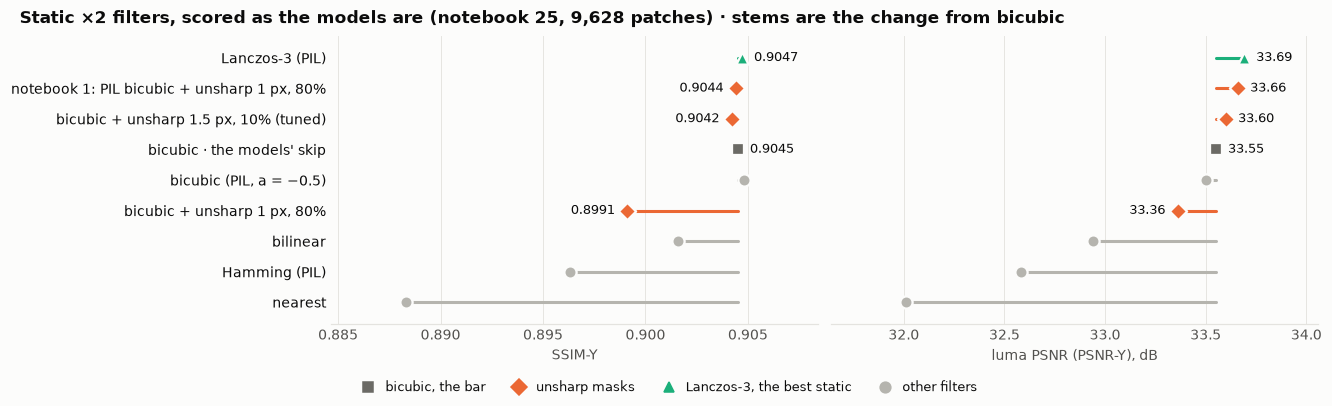

,SSIM-Y,PSNR-Y
filter,,
Lanczos-3 (PIL),0.9047,33.69
"notebook 1: PIL bicubic + unsharp 1 px, 80%",0.9044,33.66
"bicubic + unsharp 1.5 px, 10% (tuned)",0.9042,33.60
bicubic · the models' skip,0.9045,33.55
"bicubic (PIL, a = −0.5)",0.9048,33.50
"bicubic + unsharp 1 px, 80%",0.8991,33.36
bilinear,0.9016,32.94
Hamming (PIL),0.8963,32.58
nearest,0.8883,32.01


In [2]:
"""Notebook 25's saved output: every static ×2 filter on notebook 21's 9,628 validation patches, scored by
training.evaluate as notebooks 22-24 score the models. Bicubic is models.bicubic (a = -0.75), the models' skip; the
unsharp masks are on it, except notebook 1's own pipeline (PIL's bicubic, a = -0.5, then PIL's UnsharpMask). The tuned
mask is the best of a radius × amount grid on 8,000 training patches, by luma PSNR; by SSIM-Y no setting beat bicubic."""

static = pd.DataFrame(
    [("Lanczos-3 (PIL)", 0.9047, 33.69, "alt2"),
     ("notebook 1: PIL bicubic + unsharp 1 px, 80%", 0.9044, 33.66, "alt"),
     ("bicubic + unsharp 1.5 px, 10% (tuned)", 0.9042, 33.60, "alt"),
     ("bicubic · the models' skip", 0.9045, 33.55, "baseline"),
     ("bicubic (PIL, a = −0.5)", 0.9048, 33.50, "other"),
     ("bicubic + unsharp 1 px, 80%", 0.8991, 33.36, "alt"),
     ("bilinear", 0.9016, 32.94, "other"),
     ("Hamming (PIL)", 0.8963, 32.58, "other"),
     ("nearest", 0.8883, 32.01, "other")],
    columns=["filter", "SSIM-Y", "PSNR-Y", "role"]).set_index("filter")
roles, base = list(static["role"]), static.loc["bicubic · the models' skip"]
shown = ("baseline", "alt", "alt2")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, layout="constrained")
dots(axes[0], static["SSIM-Y"], roles, "SSIM-Y", reference=base["SSIM-Y"], fmt="{:.4f}", labelled=shown)
dots(axes[1], static["PSNR-Y"], roles, "luma PSNR (PSNR-Y), dB", reference=base["PSNR-Y"], labelled=shown)
title(fig, "Static ×2 filters, scored as the models are (notebook 25, 9,628 patches) · stems are the change from bicubic")
key(fig, {"bicubic, the bar": "baseline", "unsharp masks": "alt", "Lanczos-3, the best static": "alt2",
          "other filters": "other"})
plt.show()
static.drop(columns="role")

- **No unsharp mask beats bicubic on SSIM-Y**, the score the models are chosen by. The tuned mask gains +0.05 dB of luma
  and loses 0.0004 SSIM-Y. Notebook 1's 80% at 1 px, applied to the models' bicubic, loses 0.0055 SSIM-Y and 0.19 dB.
- **Notebook 1's win was an older set and a softer kernel.** There, bicubic + unsharp read 35.30 dB against bicubic's
  34.98, in RGB PSNR on an earlier patch set, with PIL's bicubic (a = −0.5). Its exact pipeline on these patches is +0.10 dB
  over the models' bicubic and 0.0002 SSIM-Y under it.
- **Sharpening costs most on x264's frames**, which the host sends without a loop filter: the 80% mask loses 0.0104
  SSIM-Y on x264's P frames and 0.0005 on NVENC's deblocked ones (notebook 25, by encoder).
- **The best static filter is Lanczos-3**, at +0.14 dB and +0.0002 SSIM-Y. ONNX `Resize` and the GPU's sampler have no
  Lanczos. Measured against it, the told 24×2's lead would be +1.38 dB instead of +1.52.

**Bicubic is the bar**, and every later table scores against it. As an ONNX `Resize` it costs 0.1–0.2 ms a 1080p frame
in the browser (bilinear 0.098, bicubic 0.159 ms, the page's baseline graphs). The client's sampler does the same for
nothing.

### 1.2 What telling the model the stream is worth (notebook 22)

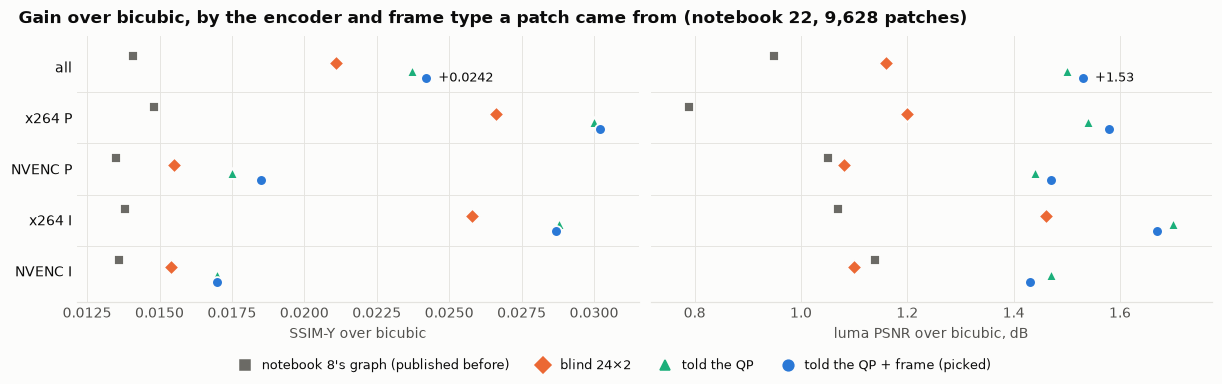

all  x264 P  NVENC P  x264 I  NVENC I
SSIM-Y over bicubic  notebook 8's graph (published before)  0.0141  0.0148   0.0135  0.0138   0.0136
                     blind 24×2                             0.0211  0.0266   0.0155  0.0258   0.0154
                     told the QP                            0.0237  0.0300   0.0175  0.0288   0.0170
                     told the QP + frame (picked)           0.0242  0.0302   0.0185  0.0287   0.0170
luma dB over bicubic notebook 8's graph (published before)  0.9500  0.7900   1.0500  1.0700   1.1400
                     blind 24×2                             1.1600  1.2000   1.0800  1.4600   1.1000
                     told the QP                            1.5000  1.5400   1.4400  1.7000   1.4700
                     told the QP + frame (picked)           1.5300  1.5800   1.4700  1.6700   1.4300

In [3]:
"""Notebook 22's closing table: gain over bicubic on notebook 21's 9,628 validation patches, by encoder and frame type.
Told models are the mean of two seeds (0.0000–0.0002 SSIM-Y apart). Bicubic itself scores 0.9045 SSIM-Y and 33.55 dB
luma on these patches (notebook 24)."""

groups = ["all", "x264 P", "NVENC P", "x264 I", "NVENC I"]
told_ssim = pd.DataFrame({"notebook 8's graph (published before)": [0.0141, 0.0148, 0.0135, 0.0138, 0.0136],
                          "blind 24×2": [0.0211, 0.0266, 0.0155, 0.0258, 0.0154],
                          "told the QP": [0.0237, 0.0300, 0.0175, 0.0288, 0.0170],
                          "told the QP + frame (picked)": [0.0242, 0.0302, 0.0185, 0.0287, 0.0170]}, index=groups)
told_db = pd.DataFrame({"notebook 8's graph (published before)": [0.95, 0.79, 1.05, 1.07, 1.14],
                        "blind 24×2": [1.16, 1.20, 1.08, 1.46, 1.10],
                        "told the QP": [1.50, 1.54, 1.44, 1.70, 1.47],
                        "told the QP + frame (picked)": [1.53, 1.58, 1.47, 1.67, 1.43]}, index=groups)
series = dict(zip(told_ssim.columns, ["baseline", "alt", "alt2", "picked"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, layout="constrained")
dodged(axes[0], told_ssim, series, "SSIM-Y over bicubic", fmt="+{:.4f}", labelled_row="all")
dodged(axes[1], told_db, series, "luma PSNR over bicubic, dB", fmt="+{:.2f}", labelled_row="all")
title(fig, "Gain over bicubic, by the encoder and frame type a patch came from (notebook 22, 9,628 patches)")
key(fig, series)
plt.show()
pd.concat({"SSIM-Y over bicubic": told_ssim, "luma dB over bicubic": told_db}, axis=1).T

- **Telling the model about the stream is worth more than the model change.** The blind 24×2 trained on these
  patches beats notebook 8's graph by +0.0070 SSIM-Y. Told the slice QP it gains another +0.0026, and told the loop
  filter and frame type, another +0.0005.
- **The frame flags help NVENC.** On NVENC's P frames, "told the QP + frame" is +0.0010 over "told the QP", five times
  the seed gap. With the QP alone, the model mixes up x264's blocky frames and NVENC's deblocked ones at the same QP.
- The client computes the condition once a frame from what `stream-h264.js` already parses, so it costs no per-pixel
  work. Notebook 23 exports this model as `upscale.onnx`, and the exported graph scores what the trained model scores
  (to 1.5e-8 SSIM-Y).

### 1.3 The picked model and its fast twin (notebook 24)

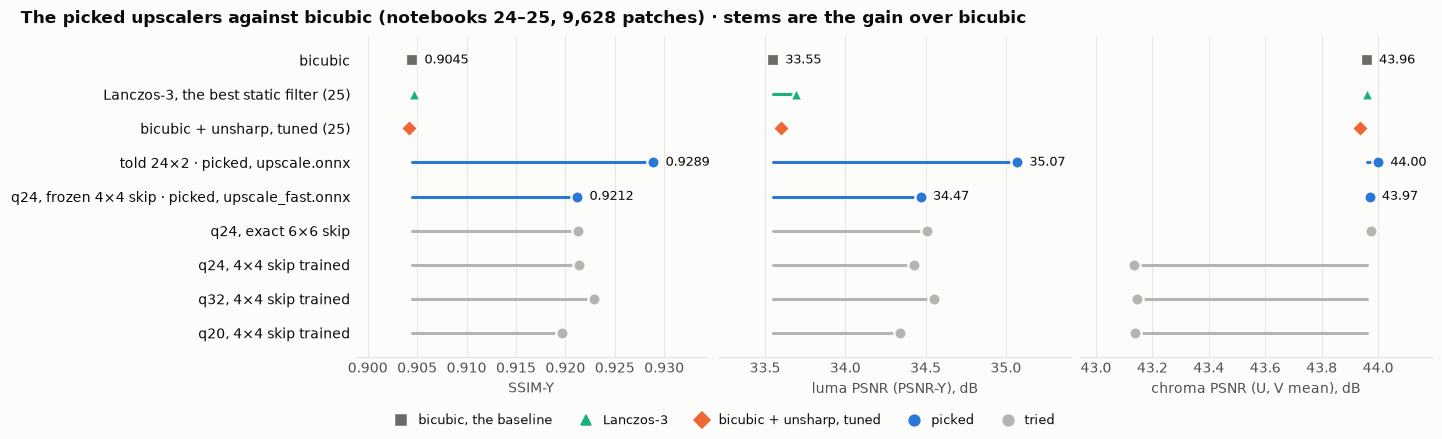

,SSIM-Y,PSNR-Y,PSNR-U,PSNR-V,MAC / LR px
model,,,,,
bicubic,0.9045,33.55,43.99,43.93,NaN
"Lanczos-3, the best static filter (25)",0.9047,33.69,43.99,43.93,NaN
"bicubic + unsharp, tuned (25)",0.9042,33.60,43.96,43.91,NaN
"told 24×2 · picked, upscale.onnx",0.9289,35.07,44.03,43.97,13000.0
"q24, frozen 4×4 skip · picked, upscale_fast.onnx",0.9212,34.47,44.00,43.94,1824.0
"q24, exact 6×6 skip",0.9213,34.51,44.00,43.95,1824.0
"q24, 4×4 skip trained",0.9214,34.43,43.04,43.23,1824.0
"q32, 4×4 skip trained",0.9229,34.55,43.03,43.26,3072.0
"q20, 4×4 skip trained",0.9197,34.34,43.06,43.22,1320.0


In [4]:
"""Notebook 24's closing table, on the same 9,628 patches: SSIM-Y, luma PSNR and chroma PSNR (the mean of U and V).
Two-seed models are the mean of their seeds (0.0001–0.0003 SSIM-Y apart). Every q model is told the same three numbers.
The two static filters closest to bicubic are notebook 25's, scored on the same patches by the same code."""

fast = pd.DataFrame(
    [("bicubic", 0.9045, 33.55, 43.99, 43.93, np.nan),
     ("Lanczos-3, the best static filter (25)", 0.9047, 33.69, 43.99, 43.93, np.nan),
     ("bicubic + unsharp, tuned (25)", 0.9042, 33.60, 43.96, 43.91, np.nan),
     ("told 24×2 · picked, upscale.onnx", 0.9289, 35.07, 44.03, 43.97, 13000),
     ("q24, frozen 4×4 skip · picked, upscale_fast.onnx", 0.9212, 34.47, 44.00, 43.94, 1824),
     ("q24, exact 6×6 skip", 0.9213, 34.51, 44.00, 43.95, 1824),
     ("q24, 4×4 skip trained", 0.9214, 34.43, 43.04, 43.23, 1824),
     ("q32, 4×4 skip trained", 0.9229, 34.55, 43.03, 43.26, 3072),
     ("q20, 4×4 skip trained", 0.9197, 34.34, 43.06, 43.22, 1320)],
    columns=["model", "SSIM-Y", "PSNR-Y", "PSNR-U", "PSNR-V", "MAC / LR px"]).set_index("model")
fast["PSNR-UV"] = fast[["PSNR-U", "PSNR-V"]].mean(axis=1)
roles = ["baseline", "alt2", "alt", "picked", "picked", "other", "other", "other", "other"]
base = fast.loc["bicubic"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True, layout="constrained")
dots(axes[0], fast["SSIM-Y"], roles, "SSIM-Y", reference=base["SSIM-Y"], fmt="{:.4f}")
dots(axes[1], fast["PSNR-Y"], roles, "luma PSNR (PSNR-Y), dB", reference=base["PSNR-Y"])
dots(axes[2], fast["PSNR-UV"], roles, "chroma PSNR (U, V mean), dB", reference=base["PSNR-UV"])
title(fig, "The picked upscalers against bicubic (notebooks 24–25, 9,628 patches) · stems are the gain over bicubic")
key(fig, {"bicubic, the baseline": "baseline", "Lanczos-3": "alt2", "bicubic + unsharp, tuned": "alt",
          "picked": "picked", "tried": "other"})
plt.show()
fast.drop(columns="PSNR-UV")

- **The told 24×2 is +0.0243 SSIM-Y and +1.52 dB luma over bicubic.** Against the best static filter, Lanczos-3, it
  is +0.0242 and +1.38 dB. Its colour is bicubic's, by construction: the network adds the same correction to R, G and B,
  which leaves U and V alone.
- **q24 keeps 69% of that SSIM-Y gain and 61% of the dB, with a seventh of the arithmetic** (1,824 multiply-adds an
  LR pixel against about 13,000).
- **The skip has to stay frozen.** Trained, it gives up about 1 dB of U and V (colour worse than bicubic's) and buys
  no SSIM-Y. Frozen, the 4×4 skip is within 0.04 dB of luma of the exact 6×6 and costs half as much.

### 1.4 Quality against time

findfont: Failed to find font weight semibold, now using 700.


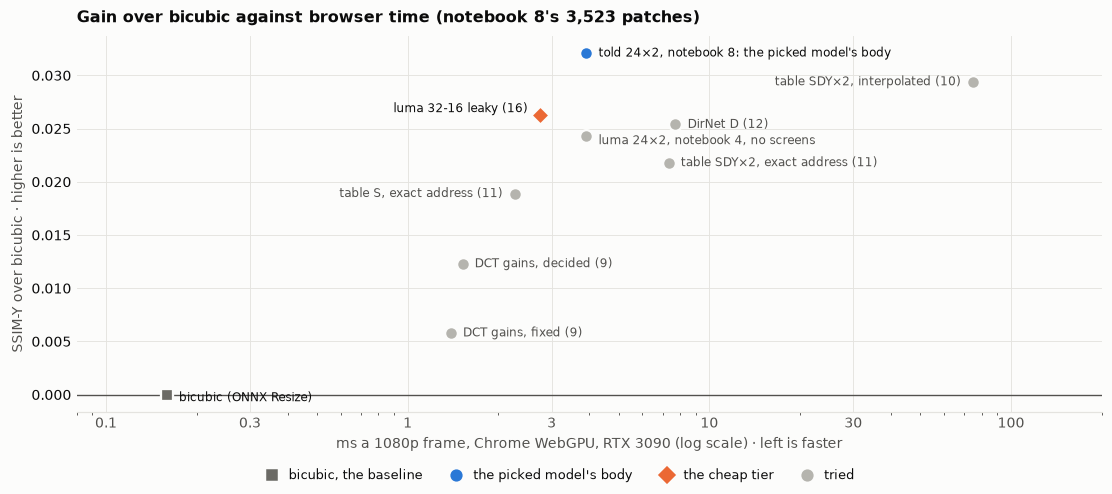

,SSIM-Y over bicubic,ms a 1080p frame
model,,
bicubic (ONNX Resize),0.0000,0.159
"DCT gains, fixed (9)",0.0058,1.390
"DCT gains, decided (9)",0.0123,1.520
"table S, exact address (11)",0.0189,2.270
luma 32-16 leaky (16),0.0263,2.750
"luma 24×2, notebook 4, no screens",0.0243,3.910
"told 24×2, notebook 8: the picked model's body",0.0321,3.910
"table SDY×2, exact address (11)",0.0218,7.330
DirNet D (12),0.0254,7.720


In [5]:
"""Every model family on notebook 8's 3,523 validation patches (SSIM-Y, from upscale/summary.md's "Where that leaves it"
and notebooks 9–11), against the time of a 1080p frame in Chrome's WebGPU on the RTX 3090 (summary.md, "Results at the
client's tile": the float16 whole-frame graph where there is one, float32 for the tables of notebook 11, nine float32
tiles for notebook 10's table, which refuses graph capture). That set is not notebook 21's, so the chart shows each
model's gain over bicubic on its own set (bicubic scores 0.9049 there) and never an absolute score. The picked model is
notebook 8's body told more about the stream; it was scored on notebook 21's set (above), not on this one."""

BICUBIC_ON_NOTEBOOK_8 = 0.9049

landscape = pd.DataFrame(
    [("bicubic (ONNX Resize)", 0.9049, 0.159, "baseline", (8, -2)),
     ("DCT gains, fixed (9)", 0.9107, 1.39, "other", (8, 0)),
     ("DCT gains, decided (9)", 0.9172, 1.52, "other", (8, 0)),
     ("table S, exact address (11)", 0.9238, 2.27, "other", (-8, 0)),
     ("luma 32-16 leaky (16)", 0.9312, 2.75, "alt", (-8, 4)),
     ("luma 24×2, notebook 4, no screens", 0.9292, 3.91, "other", (8, -3)),
     ("told 24×2, notebook 8: the picked model's body", 0.9370, 3.91, "picked", (8, 0)),
     ("table SDY×2, exact address (11)", 0.9267, 7.33, "other", (8, 0)),
     ("DirNet D (12)", 0.9303, 7.72, "other", (8, 0)),
     ("table SDY×2, interpolated (10)", 0.9343, 75.0, "other", (-8, 0))],
    columns=["model", "SSIM-Y", "ms a 1080p frame", "role", "label at"]).set_index("model")
landscape["SSIM-Y over bicubic"] = landscape["SSIM-Y"] - BICUBIC_ON_NOTEBOOK_8

fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
ax.axhline(0, color=MUTED, lw=0.9, zorder=1)
for name, r in landscape.iterrows():
    ax.scatter(r["ms a 1080p frame"], r["SSIM-Y over bicubic"], s=70, color=ROLE[r["role"]], marker=MARKER[r["role"]],
               edgecolors=SURFACE, linewidths=1.5, zorder=3)
    dx, dy = r["label at"]
    ax.annotate(name, (r["ms a 1080p frame"], r["SSIM-Y over bicubic"]), xytext=(dx, dy), textcoords="offset points",
                ha="left" if dx > 0 else "right", va="center", fontsize=8,
                color=INK if r["role"] != "other" else MUTED)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.3, 1, 3, 10, 30, 100], ["0.1", "0.3", "1", "3", "10", "30", "100"])
ax.set_xlim(0.08, 200)
ax.set_xlabel("ms a 1080p frame, Chrome WebGPU, RTX 3090 (log scale) · left is faster")
ax.set_ylabel("SSIM-Y over bicubic · higher is better")
ax.set_title("Gain over bicubic against browser time (notebook 8's 3,523 patches)")
key(fig, {"bicubic, the baseline": "baseline", "the picked model's body": "picked", "the cheap tier": "alt",
          "tried": "other"})
plt.show()
landscape[["SSIM-Y over bicubic", "ms a 1080p frame"]]

- **Operations per pixel do not predict browser time.** The `SDY×2` table counts fewer operations than the 24×2 but
  takes 75 ms, because interpolating a 4-D table takes dozens of small operators. DirNet D does a third of the 24×2's
  arithmetic and takes twice as long.
- **The 24×2 body gives the best quality for its time**: +0.032 SSIM-Y over bicubic for 3.9 ms a 1080p frame on the
  RTX 3090. The leaky 32-16 is the cheaper tier (2.8 ms), at +0.026.

### 1.5 60 fps on a GTX 1660 Ti

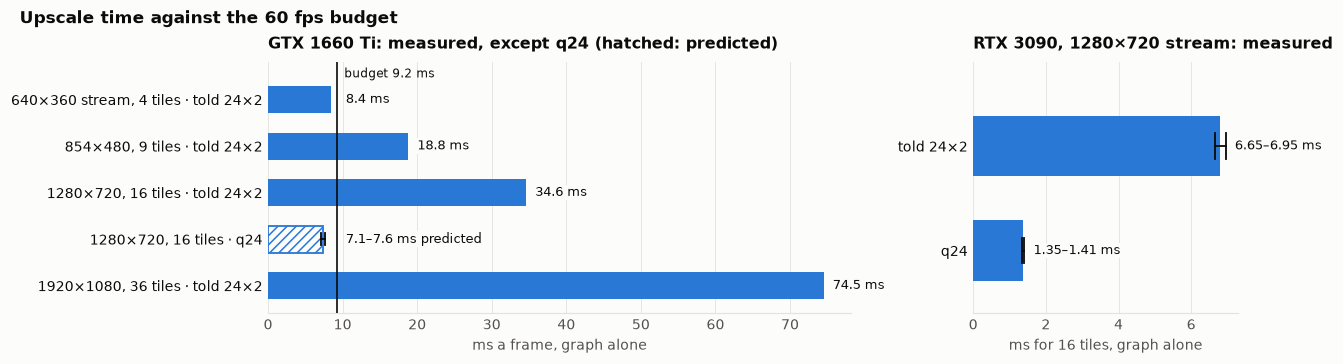

,ms,low,high,predicted
stream,,,,
"640×360 stream, 4 tiles · told 24×2",8.40,NaN,NaN,False
"854×480, 9 tiles · told 24×2",18.80,NaN,NaN,False
"1280×720, 16 tiles · told 24×2",34.60,NaN,NaN,False
"1280×720, 16 tiles · q24",7.35,7.1,7.6,True
"1920×1080, 36 tiles · told 24×2",74.50,NaN,NaN,False


In [6]:
"""upscale/reference_60fps.md and notebook 24. Left: the told 24×2 (float16) on the GTX 1660 Ti, graph alone on the
benchmark page, measured on that laptop (2026-11-12), by stream size and tile count. The model's budget is 9.2 ms a
frame: 60 fps with 20% to spare (13.3 ms), less the 2.2–4.1 ms the client spends around the graph. q24 has not run on
that card yet; its time is predicted from the RTX 3090 (notebook 24). Right: both models on the RTX 3090 at a 1280×720
stream's 16 tiles, measured in the same sessions (graph alone, float16)."""

gtx = pd.DataFrame(
    [("640×360 stream, 4 tiles · told 24×2", 8.4, np.nan, np.nan, "picked", False),
     ("854×480, 9 tiles · told 24×2", 18.8, np.nan, np.nan, "picked", False),
     ("1280×720, 16 tiles · told 24×2", 34.6, np.nan, np.nan, "picked", False),
     ("1280×720, 16 tiles · q24", 7.35, 7.1, 7.6, "picked", True),
     ("1920×1080, 36 tiles · told 24×2", 74.5, np.nan, np.nan, "picked", False)],
    columns=["stream", "ms", "low", "high", "role", "predicted"]).set_index("stream")
rtx = pd.DataFrame(
    [("told 24×2", 6.8, 6.65, 6.95, "picked", False),
     ("q24", 1.38, 1.35, 1.41, "picked", False)],
    columns=["model", "ms", "low", "high", "role", "predicted"]).set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), width_ratios=[2.2, 1], layout="constrained")
timebars(axes[0], gtx, "ms a frame, graph alone", budget=9.2, budget_label="budget 9.2 ms")
axes[0].set_title("GTX 1660 Ti: measured, except q24 (hatched: predicted)")
timebars(axes[1], rtx, "ms for 16 tiles, graph alone")
axes[1].set_title("RTX 3090, 1280×720 stream: measured")
title(fig, "Upscale time against the 60 fps budget")
plt.show()
gtx.drop(columns="role")

The told 24×2 fits the budget only for a 640×360 stream on the GTX 1660 Ti. A 1280×720 stream needs it 3.8× faster.
q24 is built for that case: **7.1–7.6 ms predicted**, under the 9.2 ms budget and under the 8.3 ms notebook 24 held it
to while its time is only predicted. On the RTX 3090 it is about 5× faster than the told 24×2, and the told 24×2 itself
fits there (6.65–6.95 ms). The client can pick the upscaler by what its GPU can afford. **q24 still has to be
measured on the card** (Run 8 of `upscale/bottlenecks_gtx1660ti.md`).

### 1.6 Structure of the picked graphs

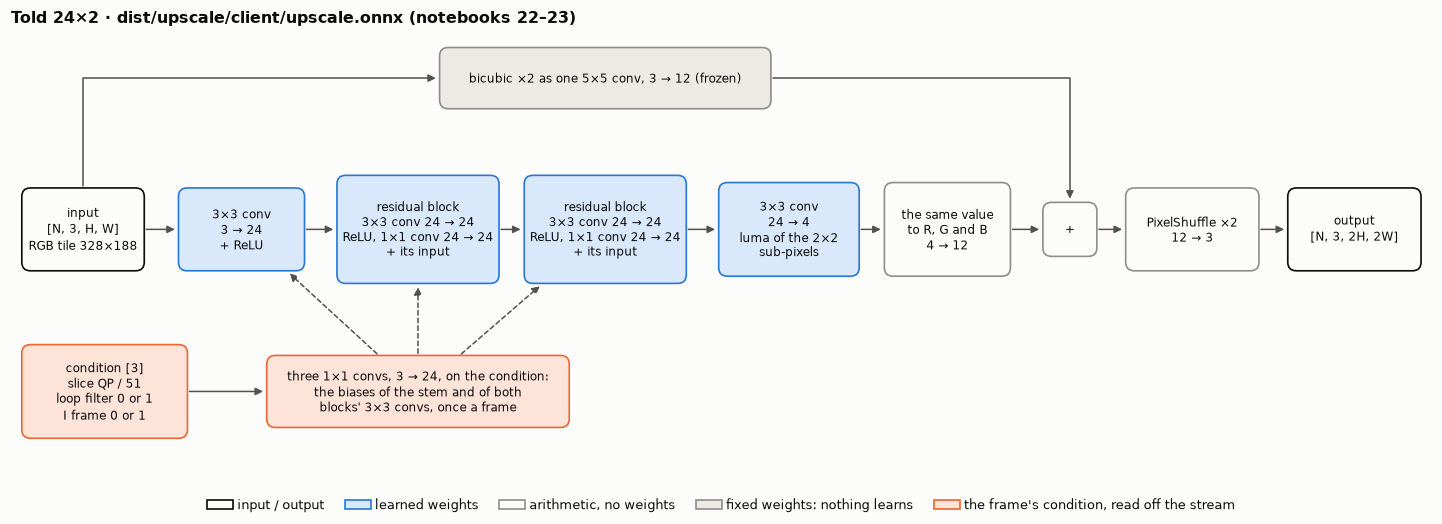

In [7]:
"""The told 24×2 as `upscale.onnx` holds it (helpers/models.py `ToldLuma`, rewritten for the client in notebook 23)."""

boxes = {
    "input":  (0.95, 3.0, 1.7, 1.15, "input\n[N, 3, H, W]\nRGB tile 328×188", "io"),
    "stem":   (3.15, 3.0, 1.75, 1.15, "3×3 conv\n3 → 24\n+ ReLU", "learned"),
    "block1": (5.6, 3.0, 2.25, 1.5, "residual block\n3×3 conv 24 → 24\nReLU, 1×1 conv 24 → 24\n+ its input", "learned"),
    "block2": (8.2, 3.0, 2.25, 1.5, "residual block\n3×3 conv 24 → 24\nReLU, 1×1 conv 24 → 24\n+ its input", "learned"),
    "tail":   (10.75, 3.0, 1.95, 1.3, "3×3 conv\n24 → 4\nluma of the 2×2\nsub-pixels", "learned"),
    "copy":   (12.95, 3.0, 1.75, 1.3, "the same value\nto R, G and B\n4 → 12", "op"),
    "add":    (14.65, 3.0, 0.75, 0.75, "+", "op"),
    "shuffle": (16.35, 3.0, 1.85, 1.15, "PixelShuffle ×2\n12 → 3", "op"),
    "output": (18.6, 3.0, 1.85, 1.15, "output\n[N, 3, 2H, 2W]", "io"),
    "skip":   (8.2, 5.1, 4.6, 0.85, "bicubic ×2 as one 5×5 conv, 3 → 12 (frozen)", "fixed"),
    "cond":   (1.25, 0.75, 2.3, 1.3, "condition [3]\nslice QP / 51\nloop filter 0 or 1\nI frame 0 or 1", "told"),
    "biases": (5.6, 0.75, 4.2, 1.0, "three 1×1 convs, 3 → 24, on the condition:\nthe biases of the stem and of both\nblocks' 3×3 convs, once a frame", "told"),
}
arrows = [("input", "stem"), ("stem", "block1"), ("block1", "block2"), ("block2", "tail"), ("tail", "copy"),
          ("copy", "add"), ("add", "shuffle"), ("shuffle", "output"),
          ("input", "skip", {"bend": "angle,angleA=90,angleB=0,rad=0"}),
          ("skip", "add", {"bend": "angle,angleA=0,angleB=90,rad=0"}),
          ("cond", "biases"),
          ("biases", "stem", {"dashed": True}), ("biases", "block1", {"dashed": True}),
          ("biases", "block2", {"dashed": True})]
diagram("Told 24×2 · dist/upscale/client/upscale.onnx (notebooks 22–23)", boxes, arrows, width=13)

Per pixel this is the blind 24×2. The condition only moves three convolutions' biases, once a frame. It costs about
13,000 multiply-adds an LR pixel and reads exactly the client's 4 px halo. The tail starts at zero, so the untrained
model is bicubic exactly. It ships at float32, with a float16 twin for a GPU with `shader-f16`.

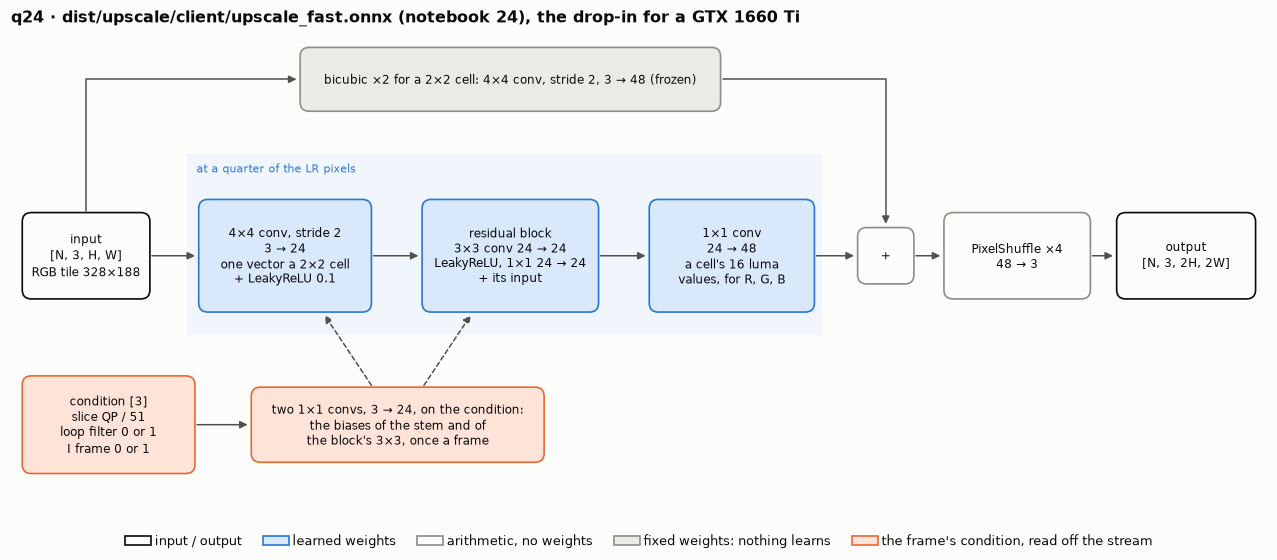

In [8]:
"""q24 with its frozen skip as `upscale_fast.onnx` holds it (helpers/models.py `FastLuma`, `FastLumaShipped`;
notebook 24)."""

boxes = {
    "input":  (0.95, 3.0, 1.7, 1.15, "input\n[N, 3, H, W]\nRGB tile 328×188", "io"),
    "stem":   (3.6, 3.0, 2.3, 1.5, "4×4 conv, stride 2\n3 → 24\none vector a 2×2 cell\n+ LeakyReLU 0.1", "learned"),
    "block":  (6.6, 3.0, 2.35, 1.5, "residual block\n3×3 conv 24 → 24\nLeakyReLU, 1×1 24 → 24\n+ its input", "learned"),
    "tail":   (9.55, 3.0, 2.2, 1.5, "1×1 conv\n24 → 48\na cell's 16 luma\nvalues, for R, G, B", "learned"),
    "add":    (11.6, 3.0, 0.75, 0.75, "+", "op"),
    "shuffle": (13.35, 3.0, 1.95, 1.15, "PixelShuffle ×4\n48 → 3", "op"),
    "output": (15.6, 3.0, 1.85, 1.15, "output\n[N, 3, 2H, 2W]", "io"),
    "skip":   (6.6, 5.35, 5.6, 0.85, "bicubic ×2 for a 2×2 cell: 4×4 conv, stride 2, 3 → 48 (frozen)", "fixed"),
    "cond":   (1.25, 0.75, 2.3, 1.3, "condition [3]\nslice QP / 51\nloop filter 0 or 1\nI frame 0 or 1", "told"),
    "biases": (5.1, 0.75, 3.9, 1.0, "two 1×1 convs, 3 → 24, on the condition:\nthe biases of the stem and of\nthe block's 3×3, once a frame", "told"),
}
arrows = [("input", "stem"), ("stem", "block"), ("block", "tail"), ("tail", "add"), ("add", "shuffle"),
          ("shuffle", "output"),
          ("input", "skip", {"bend": "angle,angleA=90,angleB=0,rad=0"}),
          ("skip", "add", {"bend": "angle,angleA=0,angleB=90,rad=0"}),
          ("cond", "biases"), ("biases", "stem", {"dashed": True}), ("biases", "block", {"dashed": True})]
diagram("q24 · dist/upscale/client/upscale_fast.onnx (notebook 24), the drop-in for a GTX 1660 Ti", boxes, arrows,
        width=11.5, bands=[(2.3, 1.95, 10.75, 4.35, "at a quarter of the LR pixels")])

It has the same inputs, output and 4 px halo as `upscale.onnx`, so it is a drop-in. The body works on 2×2 LR cells,
which lets the same multiply-adds cover twice the reach; it reads 3 LR px. It costs 1,824 multiply-adds an LR pixel. The
skip drops bicubic's outer ring of taps (0.023 of its weight) and keeps bicubic's colour to 0.01 dB.

## 2 · Frame extrapolation

2x frame generation with no added latency. The host sends every second frame of the display rate, and the client
draws the frame between from the two it received last, before the next one arrives: received frames N−2 and N in, the
unsent N+1 out. It is the harder of the two frame problems. Nothing in N−2 and N says where a motion stops, or that a
menu is about to open.

**The baselines** are **repeat**, which shows N twice and is what the client does with no generator, and **the old
mock**, `2·N − (N−2)`. The mock continues each pixel's change, which lands on N+2 instead of N+1, and scores worse
than repeat.

**The picked model is a tile search with a carry-or-repeat decision** (notebook 13,
`dist/frame_gen_extra/extrapolate2x_tilesearch_decide_r4_s2.onnx`, the client's `extrapolate.onnx`). For each
328×188 tile it tries all 81 offsets within ±8 px between N−2 and N and keeps one motion. These are fixed
convolutions; nothing in the search learns. Half of that motion is carried onto N. Then a 401-weight network reads six
numbers from the search's own costs and decides, per tile, whether to carry the motion or repeat N.

**Two kinds of score.**
- *Changed samples* are 80 px spots of the validation runs where N+1 differs from N (1,129 of 3,523). Notebooks 1–3
  score every method there, in wPSNR, PSNR-Y and SSIM-Y.
- *Moving tiles* are whole validation frames cut as the client cuts them, where the search saw motion (10,800 of
  19,374), each capped at 50 dB. The later notebooks, the decision's included, score in wPSNR alone: **their per-tile
  tables keep no SSIM**. So the picked graph has no SSIM-Y of its own. The search it decides over does.

**So one baseline has two values**: repeat scores 28.96 dB on the changed samples and 37.62 on the moving tiles, whose
average includes tiles that barely change. Compare a method only with the baseline in the same chart.

### 2.1 PSNR and SSIM on the changed samples

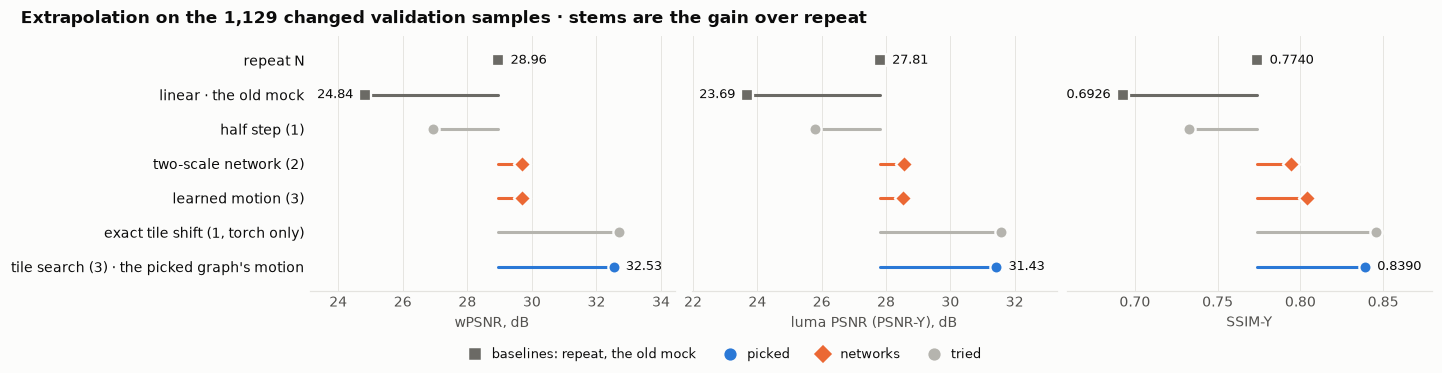

,wPSNR,PSNR-Y,SSIM-Y
method,,,
repeat N,28.96,27.81,0.7740
linear · the old mock,24.84,23.69,0.6926
half step (1),26.94,25.79,0.7326
two-scale network (2),29.68,28.56,0.7946
learned motion (3),29.68,28.53,0.8037
"exact tile shift (1, torch only)",32.69,31.57,0.8457
tile search (3) · the picked graph's motion,32.53,31.43,0.8390


In [9]:
"""Notebooks 1 and 3, saved outputs: the 1,129 changed validation samples (notebook 3's rows at a halo of 8)."""

extra_samples = pd.DataFrame(
    [("repeat N", 28.96, 27.81, 0.7740),
     ("linear · the old mock", 24.84, 23.69, 0.6926),
     ("half step (1)", 26.94, 25.79, 0.7326),
     ("two-scale network (2)", 29.68, 28.56, 0.7946),
     ("learned motion (3)", 29.68, 28.53, 0.8037),
     ("exact tile shift (1, torch only)", 32.69, 31.57, 0.8457),
     ("tile search (3) · the picked graph's motion", 32.53, 31.43, 0.8390)],
    columns=["method", "wPSNR", "PSNR-Y", "SSIM-Y"]).set_index("method")
roles = ["baseline", "baseline", "other", "alt", "alt", "other", "picked"]
base = extra_samples.loc["repeat N"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True, layout="constrained")
dots(axes[0], extra_samples["wPSNR"], roles, "wPSNR, dB", reference=base["wPSNR"])
dots(axes[1], extra_samples["PSNR-Y"], roles, "luma PSNR (PSNR-Y), dB", reference=base["PSNR-Y"])
dots(axes[2], extra_samples["SSIM-Y"], roles, "SSIM-Y", reference=base["SSIM-Y"], fmt="{:.4f}")
title(fig, "Extrapolation on the 1,129 changed validation samples · stems are the gain over repeat")
key(fig, {"baselines: repeat, the old mock": "baseline", "picked": "picked", "networks": "alt", "tried": "other"})
plt.show()
extra_samples

- **The search is +3.57 dB wPSNR and +0.065 SSIM-Y over repeat.** The old mock is −4.12 dB under it.
- **Neither network that draws comes close.** Drawing pixels (the two-scale network) or a motion per pixel gains a
  fifth of what the search does. Unsure where content goes, a network hedges, and a hedge is a blur.
- The exact tile shift is the search's idea run in torch with no softmax. The graph comes within 0.16 dB of it.

### 2.2 Whole client tiles, by kind (notebook 13)

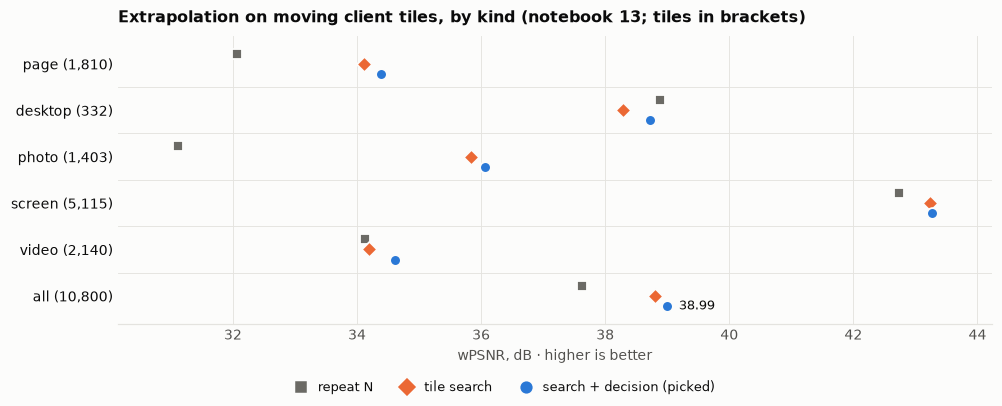

,repeat N,tile search,search + decision (picked)
"page (1,810)",32.06,34.11,34.38
desktop (332),38.88,38.29,38.72
"photo (1,403)",31.12,35.84,36.06
"screen (5,115)",42.74,43.24,43.26
"video (2,140)",34.13,34.20,34.62
"all (10,800)",37.62,38.80,38.99


In [10]:
"""Notebook 13's saved output: wPSNR on the moving validation tiles (≤ 50 dB each), by kind: drawn pages, desktops and
photos, recorded screens and 50–60 fps video. "Search + decision" is the published graph, deciding on the six numbers
it computes from the search's costs."""

extra_tiles = pd.DataFrame(
    {"repeat N": [32.06, 38.88, 31.12, 42.74, 34.13, 37.62],
     "tile search": [34.11, 38.29, 35.84, 43.24, 34.20, 38.80],
     "search + decision (picked)": [34.38, 38.72, 36.06, 43.26, 34.62, 38.99]},
    index=["page (1,810)", "desktop (332)", "photo (1,403)", "screen (5,115)", "video (2,140)", "all (10,800)"])
series = dict(zip(extra_tiles.columns, ["baseline", "alt", "picked"]))

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
dodged(ax, extra_tiles, series, "wPSNR, dB · higher is better", labelled_row="all (10,800)")
ax.set_title("Extrapolation on moving client tiles, by kind (notebook 13; tiles in brackets)")
key(fig, series)
plt.show()
extra_tiles

The search gains most where a tile moves as one: photos (pans) +4.7 dB over repeat, drawn pages (scrolls) +2.1. Recorded
screens gain +0.5 and video less, because most of a real screen's change is not one motion. Notebook 11 found only a
quarter of the changed screen tiles hold one motion of the whole tile. The decision **wins back the drawn desktops**,
where the search moved a still screen around a dragged window, and **adds +0.4 dB on video**, where a tile's change is
often no motion at all. On the changed whole tiles the old mock scores 24.86 against repeat's 29.12 (notebook 4).

### 2.3 Everything tried on top of the search

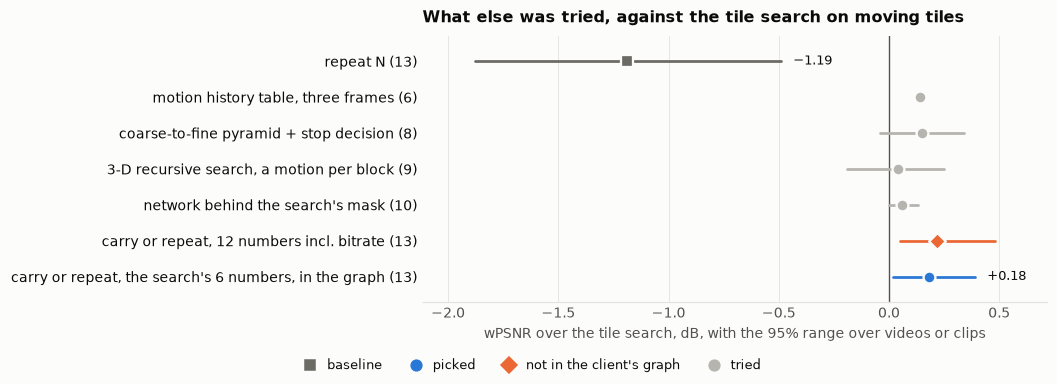

,gain,low,high
method,,,
repeat N (13),-1.19,-1.88,-0.49
"motion history table, three frames (6)",0.14,NaN,NaN
coarse-to-fine pyramid + stop decision (8),0.15,-0.04,0.34
"3-D recursive search, a motion per block (9)",0.04,-0.19,0.25
network behind the search's mask (10),0.06,0.00,0.13
"carry or repeat, 12 numbers incl. bitrate (13)",0.22,0.05,0.48
"carry or repeat, the search's 6 numbers, in the graph (13)",0.18,0.02,0.39


In [11]:
"""Gain in wPSNR over the published tile search on moving validation tiles, each notebook's own run (their tile sets
differ a little, so each gain is against the search in the same run), with its 95% range where the notebook gave one."""

extra_tried = pd.DataFrame(
    [("repeat N (13)", -1.19, -1.88, -0.49),
     ("motion history table, three frames (6)", 0.14, np.nan, np.nan),
     ("coarse-to-fine pyramid + stop decision (8)", 0.15, -0.04, 0.34),
     ("3-D recursive search, a motion per block (9)", 0.04, -0.19, 0.25),
     ("network behind the search's mask (10)", 0.06, 0.00, 0.13),
     ("carry or repeat, 12 numbers incl. bitrate (13)", 0.22, 0.05, 0.48),
     ("carry or repeat, the search's 6 numbers, in the graph (13)", 0.18, 0.02, 0.39)],
    columns=["method", "gain", "low", "high"]).set_index("method")
roles = ["baseline", "other", "other", "other", "other", "alt", "picked"]

fig, ax = plt.subplots(figsize=(9.5, 3.4), layout="constrained")
forest(ax, extra_tried, roles, "wPSNR over the tile search, dB, with the 95% range over videos or clips")
ax.set_title("What else was tried, against the tile search on moving tiles")
key(fig, {"baseline": "baseline", "picked": "picked", "not in the client's graph": "alt", "tried": "other"})
plt.show()
extra_tried

Only a decision clears zero over its whole range. The 12-number version reads the stream's bitrate and four
full-resolution measurements; those cost 8.5 ms of GPU a 1080p frame, more than the search itself. The six numbers the
search's own costs give keep most of the gain (+0.18 dB) for almost nothing. The pyramid's stop decision needs per-tile
state the client does not keep. 3-D recursive search costs 14 times the work for +0.04.

### 2.4 Time in the browser

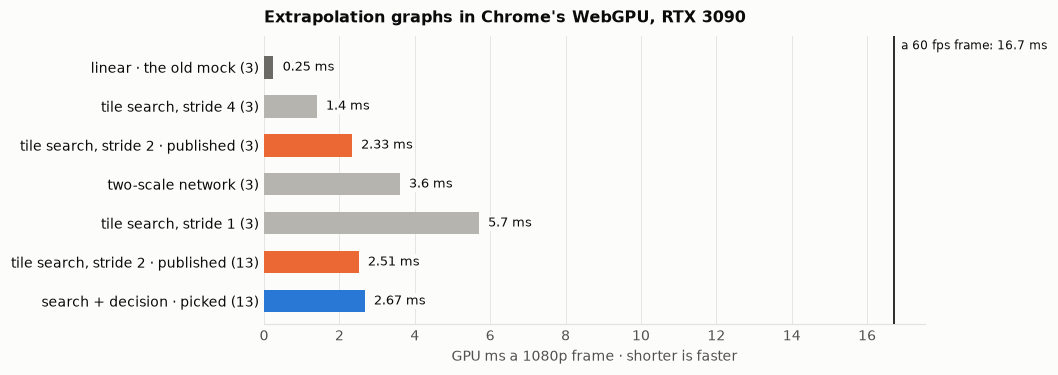

,ms
graph,
linear · the old mock (3),0.25
"tile search, stride 4 (3)",1.40
"tile search, stride 2 · published (3)",2.33
two-scale network (3),3.60
"tile search, stride 1 (3)",5.70
"tile search, stride 2 · published (13)",2.51
search + decision · picked (13),2.67


In [12]:
"""One 1080p frame as 36 tiles in one run, Chrome WebGPU on the RTX 3090, GPU time. Notebook 3's session (on the first
data set; the graphs' work does not depend on the data) and notebook 13's session, which timed the published pair; their
search rows differ by 0.2 ms between sessions. Wall-clock time in notebook 13: 2.58 and 2.75 ms."""

extra_time = pd.DataFrame(
    [("linear · the old mock (3)", 0.25, "baseline"),
     ("tile search, stride 4 (3)", 1.4, "other"),
     ("tile search, stride 2 · published (3)", 2.33, "alt"),
     ("two-scale network (3)", 3.6, "other"),
     ("tile search, stride 1 (3)", 5.7, "other"),
     ("tile search, stride 2 · published (13)", 2.51, "alt"),
     ("search + decision · picked (13)", 2.67, "picked")],
    columns=["graph", "ms", "role"]).set_index("graph")

fig, ax = plt.subplots(figsize=(9.5, 3.3), layout="constrained")
timebars(ax, extra_time, "GPU ms a 1080p frame · shorter is faster", budget=16.7,
         budget_label="a 60 fps frame: 16.7 ms")
ax.set_title("Extrapolation graphs in Chrome's WebGPU, RTX 3090")
plt.show()
extra_time.drop(columns="role")

The decision adds 0.16 ms of GPU (7% more wall time) to the search. All its work is on 81 numbers a tile, and every node
stays on the WebGPU provider. The search samples its costs every second position (stride 2), which matches stride 1's
score at less than half the time. It takes a seventh of a 60 fps frame. The search does not run on WebGL
(`GridSample`), so the client offers extrapolation on WebGPU only.

### 2.5 Structure of the picked graph

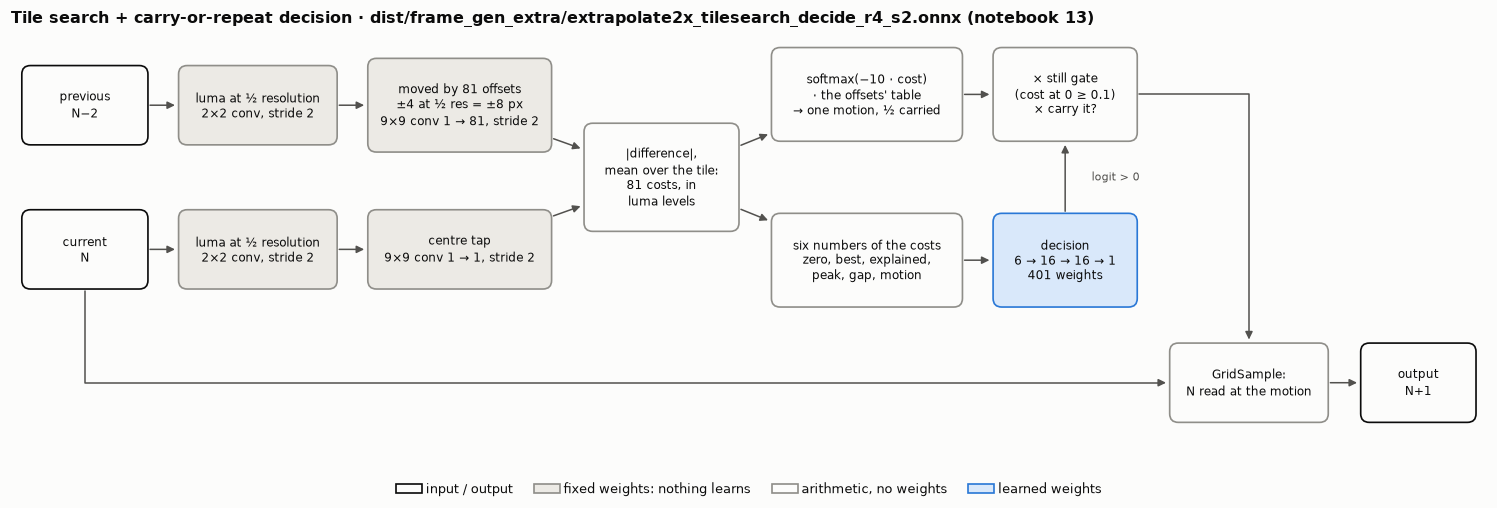

In [13]:
"""extrapolate2x_tilesearch_decide_r4_s2.onnx: helpers/models.py `TileSearch(4, 2, 10, stride 2, ½, still 0.1)` inside
`Decided`, whose decision is the 6 → 16 → 16 → 1 network of notebook 13."""

boxes = {
    "prev":    (0.95, 4.6, 1.75, 1.1, "previous\nN−2", "io"),
    "cur":     (0.95, 2.6, 1.75, 1.1, "current\nN", "io"),
    "lumaP":   (3.35, 4.6, 2.2, 1.1, "luma at ½ resolution\n2×2 conv, stride 2", "fixed"),
    "lumaC":   (3.35, 2.6, 2.2, 1.1, "luma at ½ resolution\n2×2 conv, stride 2", "fixed"),
    "moved":   (6.15, 4.6, 2.55, 1.3, "moved by 81 offsets\n±4 at ½ res = ±8 px\n9×9 conv 1 → 81, stride 2", "fixed"),
    "centre":  (6.15, 2.6, 2.55, 1.1, "centre tap\n9×9 conv 1 → 1, stride 2", "fixed"),
    "cost":    (8.95, 3.6, 2.15, 1.5, "|difference|,\nmean over the tile:\n81 costs, in\nluma levels", "op"),
    "motion":  (11.8, 4.75, 2.65, 1.3, "softmax(−10 · cost)\n· the offsets' table\n→ one motion, ½ carried", "op"),
    "feats":   (11.8, 2.45, 2.65, 1.3, "six numbers of the costs\nzero, best, explained,\npeak, gap, motion", "op"),
    "mlp":     (14.55, 2.45, 2.0, 1.3, "decision\n6 → 16 → 16 → 1\n401 weights", "learned"),
    "gate":    (14.55, 4.75, 2.0, 1.3, "× still gate\n(cost at 0 ≥ 0.1)\n× carry it?", "op"),
    "warp":    (17.1, 0.75, 2.2, 1.1, "GridSample:\nN read at the motion", "op"),
    "out":     (19.45, 0.75, 1.6, 1.1, "output\nN+1", "io"),
}
arrows = [("prev", "lumaP"), ("cur", "lumaC"), ("lumaP", "moved"), ("lumaC", "centre"), ("moved", "cost"),
          ("centre", "cost"), ("cost", "motion"), ("cost", "feats"), ("feats", "mlp"),
          ("motion", "gate"), ("mlp", "gate", {"label": "logit > 0", "at": (15.25, 3.6)}),
          ("gate", "warp", {"bend": "angle,angleA=0,angleB=90,rad=0"}),
          ("cur", "warp", {"bend": "angle,angleA=-90,angleB=180,rad=0"}),
          ("warp", "out")]
diagram("Tile search + carry-or-repeat decision · dist/frame_gen_extra/extrapolate2x_tilesearch_decide_r4_s2.onnx "
        "(notebook 13)", boxes, arrows, width=13.5)

Each 328×188 tile gets one motion for the whole tile, from 479 operations a pixel of fixed convolutions. The decision
reads only the 81 costs the search already has, so past the search all the work is on 81 numbers a tile. Where the
decision says repeat, or the tile did not change, the motion is zero and N comes back as it is. The inputs `previous`
and `current` and the output are each `[N, 3, H, W]`. The client's 3x twin carries a third of the motion.

## 3 · Frame interpolation

2x frame generation by interpolation. Once received frame N+2 is in, the client draws the unsent N+1 from N and N+2
and shows it before N+2. Both ends of the motion are known, so the model fills in rather than guesses. The price is
latency: every frame is shown half a received interval late.

**The baselines** are **the old mock**, the mean of N and N+2, which draws every moving edge twice at half strength,
and **hold N**, which repeats a frame.

**The picked model is a two-sided tile search** (notebooks 1 and 3,
`dist/frame_gen_intra/interpolate2x_tilesearch_r4_s2.onnx`, the client's `interpolate.onnx`). It is extrapolation's
search turned round: it finds the tile's motion from N to N+2, reads N half a motion back and N+2 half a motion
forward, and takes their mean. Nothing in it learns. Every learned addition tried (a network on top in notebook 2, a
per-tile decision in notebook 4) scored +0.00 dB.

The scores are the same two kinds as for extrapolation. *Changed samples* are 1,293 of 3,546 80 px spots, where N+1
differs from N or from N+2; they are scored in wPSNR, PSNR-Y and SSIM-Y. *Moving tiles* are 10,692 of 19,374 whole
client tiles, scored in wPSNR only. As there, one baseline has two values: the mock's mean scores 32.91 dB on the
changed samples and 38.15 on the moving tiles. Compare a method only with the baseline in the same chart.

### 3.1 PSNR and SSIM on the changed samples

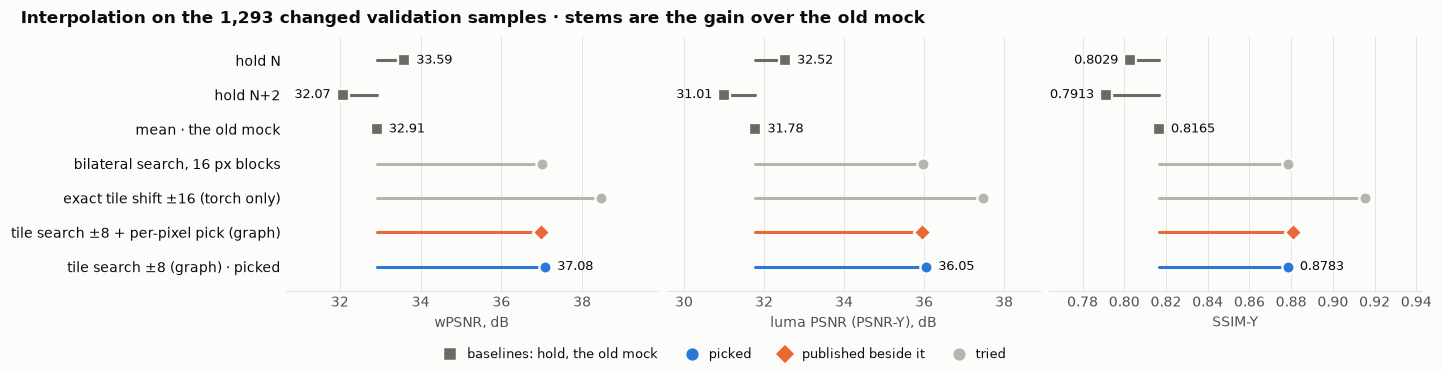

,wPSNR,PSNR-Y,SSIM-Y
method,,,
hold N,33.59,32.52,0.8029
hold N+2,32.07,31.01,0.7913
mean · the old mock,32.91,31.78,0.8165
"bilateral search, 16 px blocks",37.00,35.98,0.8786
exact tile shift ±16 (torch only),38.47,37.47,0.9152
tile search ±8 + per-pixel pick (graph),36.97,35.94,0.8810
tile search ±8 (graph) · picked,37.08,36.05,0.8783


In [14]:
"""Notebook 1's saved output: the 1,293 changed validation samples. "Graph" rows are the exported graphs' models; the exact
shift searches ±16 px in torch and has no graph."""

intra_samples = pd.DataFrame(
    [("hold N", 33.59, 32.52, 0.8029),
     ("hold N+2", 32.07, 31.01, 0.7913),
     ("mean · the old mock", 32.91, 31.78, 0.8165),
     ("bilateral search, 16 px blocks", 37.00, 35.98, 0.8786),
     ("exact tile shift ±16 (torch only)", 38.47, 37.47, 0.9152),
     ("tile search ±8 + per-pixel pick (graph)", 36.97, 35.94, 0.8810),
     ("tile search ±8 (graph) · picked", 37.08, 36.05, 0.8783)],
    columns=["method", "wPSNR", "PSNR-Y", "SSIM-Y"]).set_index("method")
roles = ["baseline", "baseline", "baseline", "other", "other", "alt", "picked"]
base = intra_samples.loc["mean · the old mock"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True, layout="constrained")
dots(axes[0], intra_samples["wPSNR"], roles, "wPSNR, dB", reference=base["wPSNR"])
dots(axes[1], intra_samples["PSNR-Y"], roles, "luma PSNR (PSNR-Y), dB", reference=base["PSNR-Y"])
dots(axes[2], intra_samples["SSIM-Y"], roles, "SSIM-Y", reference=base["SSIM-Y"], fmt="{:.4f}")
title(fig, "Interpolation on the 1,293 changed validation samples · stems are the gain over the old mock")
key(fig, {"baselines: hold, the old mock": "baseline", "picked": "picked", "published beside it": "alt",
          "tried": "other"})
plt.show()
intra_samples

- **The search is +4.17 dB wPSNR and +0.062 SSIM-Y over the mock.** On recordings the mock is worse than holding a
  frame (32.91 against 33.59), because it draws every changed line twice.
- **The exact shift's lead is reach.** It searches ±16 px and the graph ±8. On drawn pages, where scrolls move further
  than 8 px in two display frames, the gap is 5–8 dB; on recordings it is 0.2–0.5. Section 3.3 prices that reach on
  whole tiles.
- The per-pixel pick loses 0.11 dB here and gains 0.11 dB on whole tiles (3.2), all of it on the recordings.

### 3.2 Whole client tiles, by kind (notebook 3)

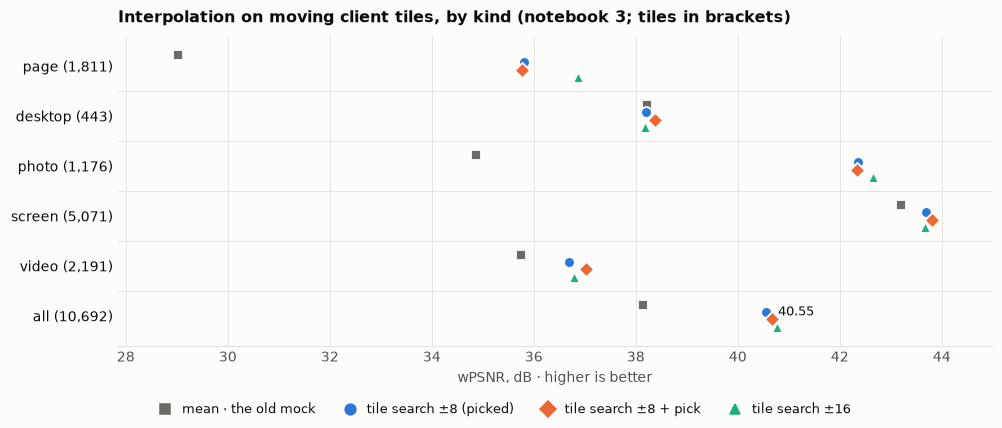

,mean · the old mock,tile search ±8 (picked),tile search ±8 + pick,tile search ±16
"page (1,811)",29.03,35.81,35.77,36.87
desktop (443),38.22,38.20,38.38,38.19
"photo (1,176)",34.86,42.35,42.33,42.65
"screen (5,071)",43.20,43.70,43.80,43.67
"video (2,191)",35.75,36.69,37.03,36.79
"all (10,692)",38.15,40.55,40.67,40.77


In [15]:
"""Notebook 3's saved output: wPSNR on the moving validation tiles (≤ 50 dB each), by kind."""

intra_tiles = pd.DataFrame(
    {"mean · the old mock": [29.03, 38.22, 34.86, 43.20, 35.75, 38.15],
     "tile search ±8 (picked)": [35.81, 38.20, 42.35, 43.70, 36.69, 40.55],
     "tile search ±8 + pick": [35.77, 38.38, 42.33, 43.80, 37.03, 40.67],
     "tile search ±16": [36.87, 38.19, 42.65, 43.67, 36.79, 40.77]},
    index=["page (1,811)", "desktop (443)", "photo (1,176)", "screen (5,071)", "video (2,191)", "all (10,692)"])
series = dict(zip(intra_tiles.columns, ["baseline", "picked", "alt", "alt2"]))

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
dodged(ax, intra_tiles, series, "wPSNR, dB · higher is better", labelled_row="all (10,692)")
ax.set_title("Interpolation on moving client tiles, by kind (notebook 3; tiles in brackets)")
key(fig, series)
plt.show()
intra_tiles

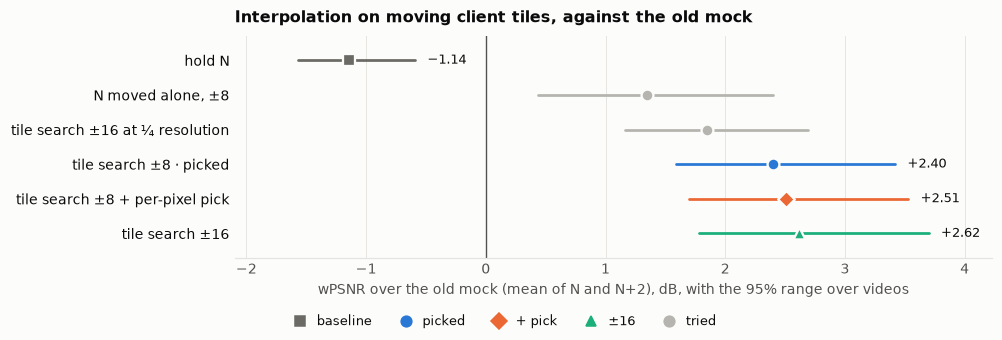

,gain,low,high
method,,,
hold N,-1.14,-1.57,-0.59
"N moved alone, ±8",1.35,0.44,2.40
tile search ±16 at ¼ resolution,1.85,1.16,2.69
tile search ±8 · picked,2.40,1.59,3.42
tile search ±8 + per-pixel pick,2.51,1.70,3.53
tile search ±16,2.62,1.78,3.70


In [16]:
"""The same tiles as gains over the old mock, with the 95% range over videos (notebook 3's saved output)."""

intra_gain = pd.DataFrame(
    [("hold N", -1.14, -1.57, -0.59),
     ("N moved alone, ±8", 1.35, 0.44, 2.40),
     ("tile search ±16 at ¼ resolution", 1.85, 1.16, 2.69),
     ("tile search ±8 · picked", 2.40, 1.59, 3.42),
     ("tile search ±8 + per-pixel pick", 2.51, 1.70, 3.53),
     ("tile search ±16", 2.62, 1.78, 3.70)],
    columns=["method", "gain", "low", "high"]).set_index("method")
roles = ["baseline", "other", "other", "picked", "alt", "alt2"]

fig, ax = plt.subplots(figsize=(9, 3.0), layout="constrained")
forest(ax, intra_gain, roles, "wPSNR over the old mock (mean of N and N+2), dB, with the 95% range over videos",
       labelled=("baseline", "picked", "alt", "alt2"))
ax.set_title("Interpolation on moving client tiles, against the old mock")
key(fig, {"baseline": "baseline", "picked": "picked", "+ pick": "alt", "±16": "alt2", "tried": "other"})
plt.show()
intra_gain

The drawn kinds carry the gain: photos +7.5 dB and pages +6.8 over the mean, against +0.9 on video and +0.5 on recorded
screens. A pan or a scroll is one motion a tile, and a screen's change mostly is not. **Moving one frame alone loses to
the search** (−1.05 dB). On this score, a change half drawn in two places beats one drawn whole in the wrong place. On
still tiles every search is within 0.02 dB of the mean. Notebook 4's learned per-tile decision among six pictures scored
40.55, the search's own score (+0.00, range −0.02 to +0.02).

### 3.3 Quality against time

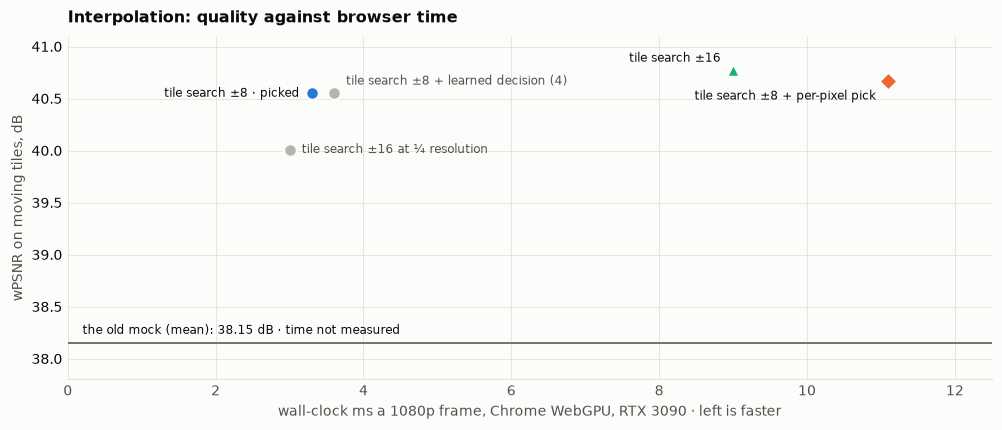

,ms a 1080p frame,wPSNR
graph,,
tile search ±8 · picked,3.3,40.55
tile search ±8 + per-pixel pick,11.1,40.67
tile search ±16,9.0,40.77
tile search ±16 at ¼ resolution,3.0,40.01
tile search ±8 + learned decision (4),3.6,40.55


In [17]:
"""Moving-tile wPSNR (notebooks 3–4) against wall-clock time of one 1080p frame as 36 tiles, Chrome 157 WebGPU on the
RTX 3090 (frame_gen_intra/summary.md, "Speed"). The old mock's browser time was not measured."""

intra_speed = pd.DataFrame(
    [("tile search ±8 · picked", 3.3, 40.55, "picked", (-8, 0)),
     ("tile search ±8 + per-pixel pick", 11.1, 40.67, "alt", (-8, -10)),
     ("tile search ±16", 9.0, 40.77, "alt2", (-8, 8)),
     ("tile search ±16 at ¼ resolution", 3.0, 40.01, "other", (8, 0)),
     ("tile search ±8 + learned decision (4)", 3.6, 40.55, "other", (8, 8))],
    columns=["graph", "ms a 1080p frame", "wPSNR", "role", "label at"]).set_index("graph")

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
ax.axhline(38.15, color=ROLE["baseline"], lw=1.2)
ax.annotate("the old mock (mean): 38.15 dB · time not measured", (0.2, 38.15), xytext=(0, 6),
            textcoords="offset points", fontsize=8, color=INK)
for name, r in intra_speed.iterrows():
    ax.scatter(r["ms a 1080p frame"], r["wPSNR"], s=70, color=ROLE[r["role"]], marker=MARKER[r["role"]],
               edgecolors=SURFACE, linewidths=1.5, zorder=3)
    dx, dy = r["label at"]
    ax.annotate(name, (r["ms a 1080p frame"], r["wPSNR"]), xytext=(dx, dy), textcoords="offset points",
                ha="left" if dx > 0 else "right", va="center", fontsize=8,
                color=INK if r["role"] != "other" else MUTED)
ax.set_xlim(0, 12.5)
ax.set_ylim(37.8, 41.1)
ax.set_xlabel("wall-clock ms a 1080p frame, Chrome WebGPU, RTX 3090 · left is faster")
ax.set_ylabel("wPSNR on moving tiles, dB")
ax.set_title("Interpolation: quality against browser time")
plt.show()
intra_speed.drop(columns=["role", "label at"])

The published ±8 search is the best the client can afford for its time: **3.3 ms a 1080p frame**, every node on the
GPU. A ±16 search is +0.22 dB, almost all of it on drawn pages, for 2.7 times the time. ±16 at a quarter of the
resolution is as cheap as ±8 but loses 0.54 dB. The pick is +0.11 dB for 3.4 times the time; it is published beside the
search, and the client runs the search. Extrapolation's search, with one `GridSample` against these two, takes 2.5 ms.

### 3.4 Structure of the picked graph

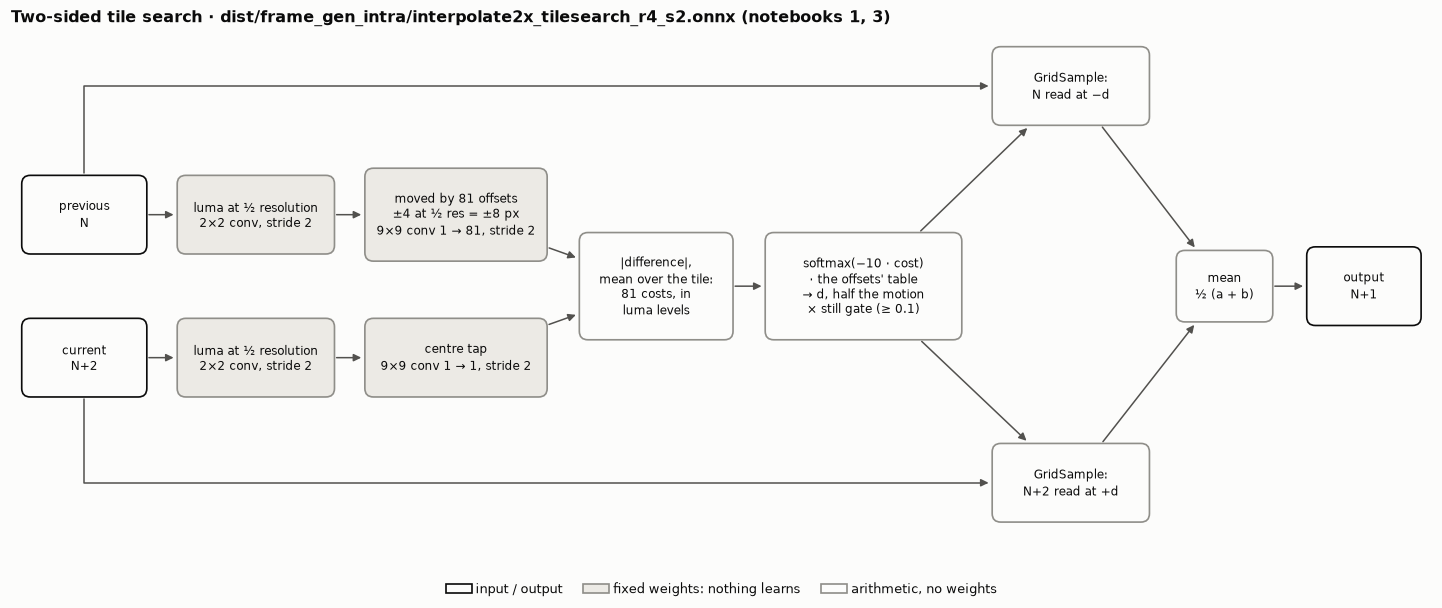

In [18]:
"""interpolate2x_tilesearch_r4_s2.onnx: helpers/models.py `Interpolate(TileSearch(4, 2, 10, stride 2, ½, still 0.1))`."""

boxes = {
    "prev":    (0.95, 4.2, 1.75, 1.1, "previous\nN", "io"),
    "cur":     (0.95, 2.2, 1.75, 1.1, "current\nN+2", "io"),
    "lumaP":   (3.35, 4.2, 2.2, 1.1, "luma at ½ resolution\n2×2 conv, stride 2", "fixed"),
    "lumaC":   (3.35, 2.2, 2.2, 1.1, "luma at ½ resolution\n2×2 conv, stride 2", "fixed"),
    "moved":   (6.15, 4.2, 2.55, 1.3, "moved by 81 offsets\n±4 at ½ res = ±8 px\n9×9 conv 1 → 81, stride 2", "fixed"),
    "centre":  (6.15, 2.2, 2.55, 1.1, "centre tap\n9×9 conv 1 → 1, stride 2", "fixed"),
    "cost":    (8.95, 3.2, 2.15, 1.5, "|difference|,\nmean over the tile:\n81 costs, in\nluma levels", "op"),
    "motion":  (11.85, 3.2, 2.75, 1.5, "softmax(−10 · cost)\n· the offsets' table\n→ d, half the motion\n× still gate (≥ 0.1)", "op"),
    "warpP":   (14.75, 6.0, 2.2, 1.1, "GridSample:\nN read at −d", "op"),
    "warpC":   (14.75, 0.45, 2.2, 1.1, "GridSample:\nN+2 read at +d", "op"),
    "mean":    (16.9, 3.2, 1.35, 1.0, "mean\n½ (a + b)", "op"),
    "out":     (18.85, 3.2, 1.6, 1.1, "output\nN+1", "io"),
}
arrows = [("prev", "lumaP"), ("cur", "lumaC"), ("lumaP", "moved"), ("lumaC", "centre"), ("moved", "cost"),
          ("centre", "cost"), ("cost", "motion"),
          ("motion", "warpP"), ("motion", "warpC"),
          ("prev", "warpP", {"bend": "angle,angleA=90,angleB=180,rad=0"}),
          ("cur", "warpC", {"bend": "angle,angleA=-90,angleB=180,rad=0"}),
          ("warpP", "mean"), ("warpC", "mean"), ("mean", "out")]
diagram("Two-sided tile search · dist/frame_gen_intra/interpolate2x_tilesearch_r4_s2.onnx (notebooks 1, 3)", boxes,
        arrows, width=13)

This is extrapolation's search with the frames turned round. The motion is measured from N to N+2, so both ends are
known, and N+1 is the mean of N moved half way forward and N+2 moved half way back. Nothing learns. The inputs
`previous` (N) and `current` (N+2) and the output are each `[N, 3, H, W]`. The client's 3x twin reads N at −⅔ of the
motion and N+2 at +⅓, and mixes them ⅓ : ⅔.

## What these numbers do not say

- **No SSIM for the whole-tile results.** The frame generators' per-tile tables (notebooks 4–13 of extrapolation, 3–4
  of interpolation) record wPSNR only. So the extrapolation decision and the interpolation pick have no SSIM-Y on
  whole tiles. Their SSIM-Y above comes from the 80 px samples, where the decision was not scored.
- **q24 has not run on a GTX 1660 Ti.** Its 7.1–7.6 ms is predicted from per-kernel ratios measured on the RTX 3090;
  the told 24×2's prediction erred 5–9% high. Its pictures have not been looked at either (the body works on 2×2
  cells).
- **The frame generators are timed on the RTX 3090 only.** That is a floor; a laptop GPU has not timed them.
- **The scores are pixel error, not what a viewer sees.** A wrong extrapolated frame shows as judder, and the mock's
  mean as a ghost. Neither generator has run in a live session yet.
- **Upscale's absolute scores are all on notebook 21's 9,628 patches, which are video only.** How the filters and
  models do on desktop screens and photos there is not measured. Section 1.4 alone uses notebook 8's set (screens
  included), as gains over bicubic.